In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [4]:
df= pd.read_csv("hotel_bookings.csv")
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [5]:
df.shape

(119390, 32)

In [6]:
df = df.drop(columns=[
    'company',
    'reservation_status',
    'reservation_status_date',                  
    'arrival_date_week_number',            
    'arrival_date_day_of_month',            
    'babies',                               
    'assigned_room_type',
    'arrival_date_year',
    'agent'
])

In [7]:
df

,hotel,is_canceled,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,meal,country,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,July,0,0,2,0.0,BB,PRT,...,0,0,C,3,No Deposit,0,Transient,0.00,0,0
1,Resort Hotel,0,737,July,0,0,2,0.0,BB,PRT,...,0,0,C,4,No Deposit,0,Transient,0.00,0,0
2,Resort Hotel,0,7,July,0,1,1,0.0,BB,GBR,...,0,0,A,0,No Deposit,0,Transient,75.00,0,0
3,Resort Hotel,0,13,July,0,1,1,0.0,BB,GBR,...,0,0,A,0,No Deposit,0,Transient,75.00,0,0
4,Resort Hotel,0,14,July,0,2,2,0.0,BB,GBR,...,0,0,A,0,No Deposit,0,Transient,98.00,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,August,2,5,2,0.0,BB,BEL,...,0,0,A,0,No Deposit,0,Transient,96.14,0,0
119386,City Hotel,0,102,August,2,5,3,0.0,BB,FRA,...,0,0,E,0,No Deposit,0,Transient,225.43,0,2
119387,City Hotel,0,34,August,2,5,2,0.0,BB,DEU,...,0,0,D,0,No Deposit,0,Transient,157.71,0,4
119388,City Hotel,0,109,August,2,5,2,0.0,BB,GBR,...,0,0,A,0,No Deposit,0,Transient,104.40,0,0


In [8]:
df.shape

(119390, 23)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_month              119390 non-null  str    
 4   stays_in_weekend_nights         119390 non-null  int64  
 5   stays_in_week_nights            119390 non-null  int64  
 6   adults                          119390 non-null  int64  
 7   children                        119386 non-null  float64
 8   meal                            119390 non-null  str    
 9   country                         118902 non-null  str    
 10  market_segment                  119390 non-null  str    
 11  distribution_channel            119390 non-null  str    
 12  is_repeated_guest          

In [10]:
df.duplicated().sum()

np.int64(33608)

In [11]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Shape before removing duplicates:", df.shape)

Total rows: 119390
Duplicate rows: 33608
Shape before removing duplicates: (119390, 23)


In [12]:
df['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

## Handling Missing Values

## Before handling missing values

In [13]:
df.isnull().sum()

hotel                               0
is_canceled                         0
lead_time                           0
arrival_date_month                  0
stays_in_weekend_nights             0
stays_in_week_nights                0
adults                              0
children                            4
meal                                0
country                           488
market_segment                      0
distribution_channel                0
is_repeated_guest                   0
previous_cancellations              0
previous_bookings_not_canceled      0
reserved_room_type                  0
booking_changes                     0
deposit_type                        0
days_in_waiting_list                0
customer_type                       0
adr                                 0
required_car_parking_spaces         0
total_of_special_requests           0
dtype: int64

In [14]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')

## After handled missing value

In [15]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
dtype: int64

## Outlier analysis

In [16]:
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()

numerical_cols.remove('is_canceled')

print(numerical_cols)

['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [18]:
outlier_bounds = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds.append({
        'Column': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound
    })

bounds_df = pd.DataFrame(outlier_bounds)

bounds_df

,Column,Lower Bound,Upper Bound
0,lead_time,-195.000,373.000
1,stays_in_weekend_nights,-3.000,5.000
2,stays_in_week_nights,-2.000,6.000
3,adults,2.000,2.000
4,children,0.000,0.000
5,is_repeated_guest,0.000,0.000
6,previous_cancellations,0.000,0.000
7,previous_bookings_not_canceled,0.000,0.000
8,booking_changes,0.000,0.000
9,days_in_waiting_list,0.000,0.000


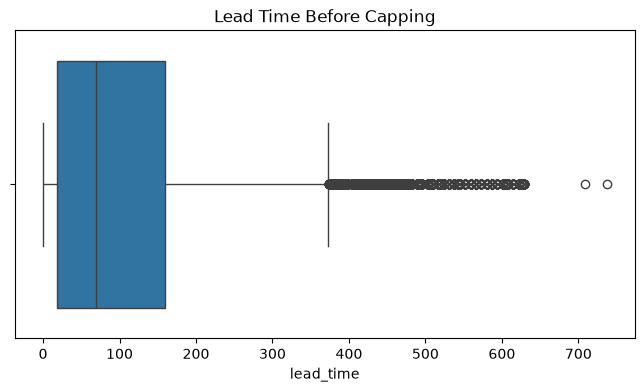

In [19]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['lead_time'])
plt.title('Lead Time Before Capping')
plt.show()


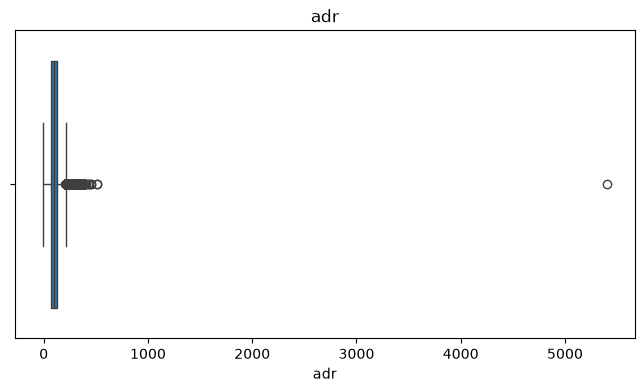

In [20]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['adr'])
plt.title('adr')
plt.show()


In [21]:
median_adr = df.loc[df['adr'] >= 0, 'adr'].median()

df.loc[df['adr'] < 0, 'adr'] = median_adr

In [22]:
df['lead_time'].describe()

count    119390.000000
mean        104.011416
std         106.863097
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64